## MASTERS THESIS — COMPREHENSIVE ML MODEL COMPARISON FOR LMD

## Models compared:
###   1. Gaussian Process Regression (GPR)
###   2. Support Vector Regression (SVR)
###   3. Random Forest (RF)
###   4. Artificial Neural Network (ANN)
###   5. Stacking Ensemble V1: RF + ANN + Ridge  (original — for comparison)
###   6. Stacking Ensemble V2: GPR + ANN + Ridge (improved design)

## Improvements over 07_all_models:
###   A. Stacking V2 properly integrated into the full evaluation pipeline
###   B. Learning curves with full visualisation and diagnosis
###   C. SHAP feature importance (bug-fixed: 4 feature names, correct explainers)
###   D. Multi-output GPR with actual kernel, evaluated vs single-output benchmark


In [21]:


# ─────────────────────────────────────────────────────────────────────────────
# CELL 1 — IMPORTS
# ─────────────────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import time
import warnings
warnings.filterwarnings('ignore')

# Sklearn — model selection
from sklearn.model_selection import (
    cross_validate, cross_val_predict, GridSearchCV,
    KFold, learning_curve
)

# Sklearn — preprocessing
from sklearn.preprocessing import StandardScaler

# Sklearn — models
from sklearn.ensemble   import RandomForestRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm        import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.linear_model import Ridge
from sklearn.multioutput import MultiOutputRegressor

# Sklearn — metrics
from sklearn.metrics import (
    mean_squared_error, r2_score,
    mean_absolute_error, mean_absolute_percentage_error
)

#import shap
# SHAP — install if needed: pip install shap


try:
    import shap
    SHAP_AVAILABLE = True
    print("✓ SHAP available")
except ImportError:
    SHAP_AVAILABLE = False
    print("⚠️  SHAP not installed. Run: pip install shap")


# Reproducibility
np.random.seed(42)

# Plot style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("=" * 80)
print("  COMPREHENSIVE MODEL COMPARISON — LMD PROCESS OPTIMISATION")
print("=" * 80)
print("✓ All packages loaded\n")


✓ SHAP available
  COMPREHENSIVE MODEL COMPARISON — LMD PROCESS OPTIMISATION
✓ All packages loaded



In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 2 — LOAD DATA
# ─────────────────────────────────────────────────────────────────────────────
print("[STEP 1] Loading dataset...")

# ── UPDATE THIS PATH ──────────────────────────────────────────────────────────
# DATA_PATH = '~/Documents/PlayTime/LMD_Modelling/data_processed/processed_data.csv'
# ─────────────────────────────────────────────────────────────────────────────

# df = pd.read_csv(DATA_PATH)
df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")

print(f"  Shape      : {df.shape}")
print(f"  Samples    : {len(df)}")
print(f"  Columns    : {df.columns.tolist()}")
print(f"\nFirst 5 rows:")
print(df.head())
print(f"\nMissing values: {df.isnull().sum().sum()}")



[STEP 1] Loading dataset...
  Shape      : (89, 21)
  Samples    : 89
  Columns    : ['sample_id', 'Power', 'Speed', 'Feed', 'width_um', 'LED_J_per_mm', 'VED_J_per_mm3', 'height_um', 'depth_um', 'angle_deg', 'aspect_ratio', 'dilution_percent', 'porosity_%', 'pore_count', 'pore_area_um2', 'meltpool_area_um2', 'bbox_xyxy', 'speed_mm_per_s', 'meltpool_area_mm2', 'A_height_um2', 'A_depth_um2']

First 5 rows:
                 sample_id  Power  Speed  Feed  width_um  LED_J_per_mm  \
0   1.0_P1860.0_V1.1_F_2.0   1860    1.1     2    2288.6    101.454545   
1  10.0_P2400.0_V1.5_F_4.5   2400    1.5     4    2480.8     96.000000   
2  11.0_P1620.0_V0.9_F_3.0   1620    0.9     3    2039.2    108.000000   
3  12.0_P2470.0_V1.0_F_7.0   2470    1.0     7    2653.1    148.200000   
4  13.0_P2440.0_V1.4_F_7.5   2440    1.4     7    2497.9    104.571429   

   VED_J_per_mm3  height_um  depth_um  angle_deg  ...  dilution_percent  \
0      85.012065     294.92    476.93     179.92  ...         61.790503 

In [6]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 3 — FEATURE ENGINEERING & SCALING
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 2] Feature Engineering & Preprocessing")
print("=" * 80)

# ── Inputs ────────────────────────────────────────────────────────────────────
# Controllable LMD process parameters
X_raw = df[['Power', 'Speed', 'Feed']].values

# Physics-informed feature: Linear Energy Density  LED = Power / Speed
# Represents the energy delivered per unit length of scan track
heat_input = X_raw[:, 0] / (X_raw[:, 1] + 1e-9)   # avoid div-by-zero

# Final feature matrix — 4 columns
X = np.column_stack([X_raw, heat_input])

# IMPORTANT: feature_names must have exactly 4 entries to match X
# This was the bug in the original SHAP code (only 3 names for 4 columns)
FEATURE_NAMES = ['Power', 'Speed', 'Feed', 'Heat_Input (P/S)']

print(f"\n  Input features : {FEATURE_NAMES}")
print(f"  Feature matrix : {X.shape}   ← {X.shape[1]} columns, {X.shape[0]} samples")

# ── Targets ────────────────────────────────────────────────────────────────────
# Primary response variables for LMD bead geometry quality
y_height = df['height_um'].values
y_aspect = df['aspect_ratio'].values

print(f"\n  Target — Height (μm)     : min={y_height.min():.1f}  max={y_height.max():.1f}"
      f"  mean={y_height.mean():.1f} ± {y_height.std():.1f}")
print(f"  Target — Aspect Ratio    : min={y_aspect.min():.3f}  max={y_aspect.max():.3f}"
      f"  mean={y_aspect.mean():.3f} ± {y_aspect.std():.3f}")

# ── Standardisation ────────────────────────────────────────────────────────────
# Required by GPR, SVR, ANN; also stabilises target space for convergence
# Targets are scaled so we can back-transform to original units for reporting
scaler_X      = StandardScaler()
scaler_height = StandardScaler()
scaler_aspect = StandardScaler()

X_scaled         = scaler_X.fit_transform(X)
y_height_scaled  = scaler_height.fit_transform(y_height.reshape(-1, 1)).ravel()
y_aspect_scaled  = scaler_aspect.fit_transform(y_aspect.reshape(-1, 1)).ravel()

print(f"\n  ✓ Features standardised  — mean≈0, std≈1")
print(f"  ✓ Targets standardised   — stored separately for back-transformation")




[STEP 2] Feature Engineering & Preprocessing

  Input features : ['Power', 'Speed', 'Feed', 'Heat_Input (P/S)']
  Feature matrix : (89, 4)   ← 4 columns, 89 samples

  Target — Height (μm)     : min=214.0  max=2432.2  mean=803.4 ± 426.2
  Target — Aspect Ratio    : min=0.078  max=1.402  mean=0.342 ± 0.215

  ✓ Features standardised  — mean≈0, std≈1
  ✓ Targets standardised   — stored separately for back-transformation


In [7]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 4 — DEFINE MODELS & HYPERPARAMETER GRIDS
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 3] Model Definitions & Hyperparameter Grids")
print("=" * 80)

# ── 1. Gaussian Process Regression ───────────────────────────────────────────
# Bayesian non-parametric model; ideal for small N; provides uncertainty bands.
# WhiteKernel handles observation noise explicitly.
gpr_base = GaussianProcessRegressor(n_restarts_optimizer=5, random_state=42)

gpr_grid = {
    'alpha' : [1e-10, 1e-5, 1e-2],
    'kernel': [
        C(1.0) * RBF(1.0),
        C(1.0) * RBF(1.0) + WhiteKernel(noise_level=1.0),
    ]
}

# ── 2. Support Vector Regression ─────────────────────────────────────────────
# Epsilon-insensitive loss makes it robust to outliers.
# RBF kernel handles non-linear relationships in the feature space.
svr_base = SVR()

svr_grid = {
    'C'      : [0.1, 1.0, 10.0, 100.0],   # Regularisation: higher C = lower bias
    'epsilon': [0.01, 0.1, 0.2],           # Tube half-width: larger = more insensitive
    'kernel' : ['rbf'],
    'gamma'  : ['scale', 'auto']            # Kernel bandwidth
}

# ── 3. Random Forest ─────────────────────────────────────────────────────────
# Bagged decision trees; no scaling needed; handles interactions naturally.
# Expected to underperform at N=89 due to high variance (shallow trees).
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_grid = {
    'n_estimators'    : [100, 200, 300],
    'max_depth'       : [None, 10, 20],
    'min_samples_leaf': [1, 2, 4],
    'max_features'    : ['sqrt', 'log2']
}

# ── 4. Artificial Neural Network ─────────────────────────────────────────────
# Multi-layer perceptron; early stopping prevents overfitting at small N.
# Learns complex non-linear feature interactions via backpropagation.
ann_base = MLPRegressor(
    early_stopping      = True,
    validation_fraction = 0.15,
    n_iter_no_change    = 20,
    max_iter            = 1000,
    random_state        = 42
)

ann_grid = {
    'hidden_layer_sizes': [(64, 32), (128, 64), (64, 32, 16)],
    'alpha'             : [0.0001, 0.001, 0.01],      # L2 weight decay
    'learning_rate_init': [0.001, 0.01],
    'activation'        : ['relu', 'tanh']
}

# Ridge meta-learner grid used by BOTH stacking variants
ridge_grid = {
    'final_estimator__alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
}

print("  GPR  — kernel search + alpha regularisation")
print("  SVR  — C, epsilon, gamma (RBF kernel)")
print("  RF   — n_estimators, max_depth, min_samples_leaf, max_features")
print("  ANN  — architecture, L2 alpha, learning rate, activation")
print("  Ridge meta-learner — alpha (shared by Stacking V1 & V2)")




[STEP 3] Model Definitions & Hyperparameter Grids
  GPR  — kernel search + alpha regularisation
  SVR  — C, epsilon, gamma (RBF kernel)
  RF   — n_estimators, max_depth, min_samples_leaf, max_features
  ANN  — architecture, L2 alpha, learning rate, activation
  Ridge meta-learner — alpha (shared by Stacking V1 & V2)


In [8]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 5 — HYPERPARAMETER TUNING HELPER
# ─────────────────────────────────────────────────────────────────────────────

def tune(model, grid, X, y, label, cv=5):
    """
    GridSearchCV wrapper.
    Returns (best_estimator, best_params, best_cv_r2).
    Prints a compact summary.
    """
    print(f"\n  {'─'*65}")
    print(f"  Tuning : {label}")
    gs = GridSearchCV(model, grid, cv=cv, scoring='r2', n_jobs=-1, verbose=0)
    t0 = time.time()
    gs.fit(X, y)
    elapsed = time.time() - t0
    print(f"  Best R² = {gs.best_score_:.4f}   params = {gs.best_params_}   ({elapsed:.1f}s)")
    return gs.best_estimator_, gs.best_params_, gs.best_score_



In [9]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 6 — TUNE BASE MODELS FOR HEIGHT
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 4A] Hyperparameter Tuning — HEIGHT")
print("=" * 80)

models_H, params_H, cv_H = {}, {}, {}

models_H['GPR'], params_H['GPR'], cv_H['GPR'] = tune(
    gpr_base, gpr_grid, X_scaled, y_height_scaled, 'GPR — Height')

models_H['SVR'], params_H['SVR'], cv_H['SVR'] = tune(
    svr_base, svr_grid, X_scaled, y_height_scaled, 'SVR — Height')

models_H['RF'],  params_H['RF'],  cv_H['RF']  = tune(
    rf_base,  rf_grid,  X_scaled, y_height_scaled, 'RF  — Height')

models_H['ANN'], params_H['ANN'], cv_H['ANN'] = tune(
    ann_base, ann_grid, X_scaled, y_height_scaled, 'ANN — Height')

print("\n  HEIGHT TUNING SUMMARY:")
for name, score in cv_H.items():
    print(f"    {name:6s} → CV R² = {score:.4f}")




[STEP 4A] Hyperparameter Tuning — HEIGHT

  ─────────────────────────────────────────────────────────────────
  Tuning : GPR — Height
  Best R² = 0.9437   params = {'alpha': 0.01, 'kernel': 1**2 * RBF(length_scale=1)}   (3.7s)

  ─────────────────────────────────────────────────────────────────
  Tuning : SVR — Height
  Best R² = 0.8300   params = {'C': 10.0, 'epsilon': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}   (0.2s)

  ─────────────────────────────────────────────────────────────────
  Tuning : RF  — Height
  Best R² = 0.7561   params = {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}   (28.8s)

  ─────────────────────────────────────────────────────────────────
  Tuning : ANN — Height
  Best R² = 0.9184   params = {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.01}   (4.9s)

  HEIGHT TUNING SUMMARY:
    GPR    → CV R² = 0.9437
    SVR    → CV R² = 0.8300
    RF     → CV R² = 0.7561
    ANN    → C

In [10]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 7 — BUILD STACKING ENSEMBLES FOR HEIGHT
# (V1: RF + ANN kept for comparison; V2: GPR + ANN — the improved design)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 5A] Stacking Ensembles — HEIGHT")
print("=" * 80)

# ── Stacking V1: RF + ANN (original design — kept to demonstrate the weakness)
print("\n  Building Stacking V1 (RF + ANN)  ←  original design, included as baseline")
sv1_H_base = StackingRegressor(
    estimators=[('rf', models_H['RF']), ('ann', models_H['ANN'])],
    final_estimator=Ridge(), cv=5, n_jobs=-1
)
models_H['Stack_V1'], params_H['Stack_V1'], cv_H['Stack_V1'] = tune(
    sv1_H_base, ridge_grid, X_scaled, y_height_scaled, 'Stacking V1 RF+ANN — Height')

# ── Stacking V2: GPR + ANN (improved design)
# Rationale: include only the strongest complementary learners.
# GPR = smooth Bayesian interpolation; ANN = non-linear function approximation.
# RF dragged V1 down because it was the weakest model (R²=0.63 for height).
print("\n  Building Stacking V2 (GPR + ANN)  ← improved design")
sv2_H_base = StackingRegressor(
    estimators=[('gpr', models_H['GPR']), ('ann', models_H['ANN'])],
    final_estimator=Ridge(), cv=5, n_jobs=-1
)
models_H['Stack_V2'], params_H['Stack_V2'], cv_H['Stack_V2'] = tune(
    sv2_H_base, ridge_grid, X_scaled, y_height_scaled, 'Stacking V2 GPR+ANN — Height')

print(f"\n  Stack V1 Ridge alpha = {params_H['Stack_V1']['final_estimator__alpha']}")
print(f"  Stack V2 Ridge alpha = {params_H['Stack_V2']['final_estimator__alpha']}")




[STEP 5A] Stacking Ensembles — HEIGHT

  Building Stacking V1 (RF + ANN)  ←  original design, included as baseline

  ─────────────────────────────────────────────────────────────────
  Tuning : Stacking V1 RF+ANN — Height
  Best R² = 0.8850   params = {'final_estimator__alpha': 1.0}   (19.2s)

  Building Stacking V2 (GPR + ANN)  ← improved design

  ─────────────────────────────────────────────────────────────────
  Tuning : Stacking V2 GPR+ANN — Height
  Best R² = 0.9300   params = {'final_estimator__alpha': 0.001}   (10.2s)

  Stack V1 Ridge alpha = 1.0
  Stack V2 Ridge alpha = 0.001


In [12]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 8 — TUNE BASE MODELS FOR ASPECT RATIO
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 4B] Hyperparameter Tuning — ASPECT RATIO")
print("=" * 80)

models_A, params_A, cv_A = {}, {}, {}

models_A['GPR'], params_A['GPR'], cv_A['GPR'] = tune(
    gpr_base, gpr_grid, X_scaled, y_aspect_scaled, 'GPR — Aspect Ratio')

models_A['SVR'], params_A['SVR'], cv_A['SVR'] = tune(
    svr_base, svr_grid, X_scaled, y_aspect_scaled, 'SVR — Aspect Ratio')

models_A['RF'],  params_A['RF'],  cv_A['RF']  = tune(
    rf_base,  rf_grid,  X_scaled, y_aspect_scaled, 'RF  — Aspect Ratio')

models_A['ANN'], params_A['ANN'], cv_A['ANN'] = tune(
    ann_base, ann_grid, X_scaled, y_aspect_scaled, 'ANN — Aspect Ratio')

print("\n  ASPECT RATIO TUNING SUMMARY:")
for name, score in cv_A.items():
    print(f"    {name:6s} → CV R² = {score:.4f}")




[STEP 4B] Hyperparameter Tuning — ASPECT RATIO

  ─────────────────────────────────────────────────────────────────
  Tuning : GPR — Aspect Ratio
  Best R² = 0.9083   params = {'alpha': 0.01, 'kernel': 1**2 * RBF(length_scale=1)}   (1.1s)

  ─────────────────────────────────────────────────────────────────
  Tuning : SVR — Aspect Ratio
  Best R² = 0.7910   params = {'C': 100.0, 'epsilon': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}   (0.2s)

  ─────────────────────────────────────────────────────────────────
  Tuning : RF  — Aspect Ratio
  Best R² = 0.7253   params = {'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 100}   (26.0s)

  ─────────────────────────────────────────────────────────────────
  Tuning : ANN — Aspect Ratio
  Best R² = 0.8787   params = {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (64, 32, 16), 'learning_rate_init': 0.01}   (6.2s)

  ASPECT RATIO TUNING SUMMARY:
    GPR    → CV R² = 0.9083
    SVR    → CV R² = 0.7910
    

In [13]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 9 — BUILD STACKING ENSEMBLES FOR ASPECT RATIO
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 5B] Stacking Ensembles — ASPECT RATIO")
print("=" * 80)

# Stacking V1: RF + ANN
sv1_A_base = StackingRegressor(
    estimators=[('rf', models_A['RF']), ('ann', models_A['ANN'])],
    final_estimator=Ridge(), cv=5, n_jobs=-1
)
models_A['Stack_V1'], params_A['Stack_V1'], cv_A['Stack_V1'] = tune(
    sv1_A_base, ridge_grid, X_scaled, y_aspect_scaled, 'Stacking V1 RF+ANN — Aspect Ratio')

# Stacking V2: GPR + ANN
sv2_A_base = StackingRegressor(
    estimators=[('gpr', models_A['GPR']), ('ann', models_A['ANN'])],
    final_estimator=Ridge(), cv=5, n_jobs=-1
)
models_A['Stack_V2'], params_A['Stack_V2'], cv_A['Stack_V2'] = tune(
    sv2_A_base, ridge_grid, X_scaled, y_aspect_scaled, 'Stacking V2 GPR+ANN — Aspect Ratio')

print(f"\n  Stack V1 Ridge alpha = {params_A['Stack_V1']['final_estimator__alpha']}")
print(f"  Stack V2 Ridge alpha = {params_A['Stack_V2']['final_estimator__alpha']}")



[STEP 5B] Stacking Ensembles — ASPECT RATIO

  ─────────────────────────────────────────────────────────────────
  Tuning : Stacking V1 RF+ANN — Aspect Ratio
  Best R² = 0.7898   params = {'final_estimator__alpha': 10.0}   (12.5s)

  ─────────────────────────────────────────────────────────────────
  Tuning : Stacking V2 GPR+ANN — Aspect Ratio
  Best R² = 0.8405   params = {'final_estimator__alpha': 10.0}   (11.2s)

  Stack V1 Ridge alpha = 10.0
  Stack V2 Ridge alpha = 10.0


In [14]:


# ─────────────────────────────────────────────────────────────────────────────
# CELL 10 — COMPREHENSIVE EVALUATION FUNCTION
# ─────────────────────────────────────────────────────────────────────────────

def evaluate(model, X, y_scaled, scaler, cv=5):
    """
    Full cross-validated evaluation of a model.
    Returns a dict with:
      - Cross-validation R², RMSE, MAE (scaled space)
      - Out-of-fold R², RMSE, MAE, MAPE in ORIGINAL UNITS (interpretable)
      - Residuals and normality p-value
      - Predicted and true values for plotting
    """
    # ── Cross-validation in scaled space ─────────────────────────────────────
    cv_res = cross_validate(
        model, X, y_scaled, cv=cv,
        scoring=['r2', 'neg_mean_squared_error', 'neg_mean_absolute_error'],
        n_jobs=-1
    )
    r2_cv   = cv_res['test_r2'].mean()
    r2_std  = cv_res['test_r2'].std()

    # ── Out-of-fold predictions → back-transform to original units ────────────
    # cross_val_predict ensures each sample is predicted on a fold it was NOT
    # trained on, giving an honest generalisation estimate
    y_pred_scaled = cross_val_predict(model, X, y_scaled, cv=cv)
    y_true_orig   = scaler.inverse_transform(y_scaled.reshape(-1, 1)).ravel()
    y_pred_orig   = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    # ── Metrics in original units ─────────────────────────────────────────────
    r2   = r2_score(y_true_orig, y_pred_orig)
    rmse = np.sqrt(mean_squared_error(y_true_orig, y_pred_orig))
    mae  = mean_absolute_error(y_true_orig, y_pred_orig)
    mape = mean_absolute_percentage_error(y_true_orig, y_pred_orig) * 100

    # ── Residuals & normality ─────────────────────────────────────────────────
    residuals = y_true_orig - y_pred_orig
    res_norm  = (residuals - residuals.mean()) / residuals.std()
    # Shapiro-Wilk: H0 = residuals are normally distributed; p<0.05 → reject
    _, norm_p = stats.shapiro(res_norm)

    return {
        'r2_cv': r2_cv, 'r2_cv_std': r2_std,
        'r2': r2, 'rmse': rmse, 'mae': mae, 'mape': mape,
        'cv_oof_gap': abs(r2_cv - r2),
        'norm_p': norm_p,
        'y_true': y_true_orig,
        'y_pred': y_pred_orig,
        'residuals': residuals
    }



In [15]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 11 — EVALUATE ALL MODELS
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 6] Evaluating All Models (5-fold CV, original units)")
print("=" * 80)

# ── Height ────────────────────────────────────────────────────────────────────
print("\n  ── HEIGHT ──────────────────────────────────────────────────────────")
res_H = {}
for name, model in models_H.items():
    t0 = time.time()
    res_H[name] = evaluate(model, X_scaled, y_height_scaled, scaler_height)
    res_H[name]['time'] = round(time.time() - t0, 2)
    r = res_H[name]
    print(f"  {name:<12}  R²={r['r2']:.4f}  RMSE={r['rmse']:.1f}μm  "
          f"MAE={r['mae']:.1f}μm  MAPE={r['mape']:.2f}%  "
          f"gap={r['cv_oof_gap']:.3f}  norm_p={r['norm_p']:.4f}  ({r['time']}s)")

# ── Aspect Ratio ──────────────────────────────────────────────────────────────
print("\n  ── ASPECT RATIO ────────────────────────────────────────────────────")
res_A = {}
for name, model in models_A.items():
    t0 = time.time()
    res_A[name] = evaluate(model, X_scaled, y_aspect_scaled, scaler_aspect)
    res_A[name]['time'] = round(time.time() - t0, 2)
    r = res_A[name]
    print(f"  {name:<12}  R²={r['r2']:.4f}  RMSE={r['rmse']:.4f}  "
          f"MAE={r['mae']:.4f}  MAPE={r['mape']:.2f}%  "
          f"gap={r['cv_oof_gap']:.3f}  norm_p={r['norm_p']:.4f}  ({r['time']}s)")




[STEP 6] Evaluating All Models (5-fold CV, original units)

  ── HEIGHT ──────────────────────────────────────────────────────────
  GPR           R²=0.9552  RMSE=90.2μm  MAE=64.6μm  MAPE=9.53%  gap=0.012  norm_p=0.0003  (0.66s)
  SVR           R²=0.7509  RMSE=212.7μm  MAE=110.7μm  MAPE=15.43%  gap=0.079  norm_p=0.0000  (0.02s)
  RF            R²=0.6844  RMSE=239.4μm  MAE=132.4μm  MAPE=17.80%  gap=0.072  norm_p=0.0000  (1.71s)
  ANN           R²=0.9401  RMSE=104.3μm  MAE=78.3μm  MAPE=11.25%  gap=0.022  norm_p=0.0000  (0.34s)
  Stack_V1      R²=0.9048  RMSE=131.5μm  MAE=94.3μm  MAPE=13.22%  gap=0.020  norm_p=0.0000  (15.82s)
  Stack_V2      R²=0.9449  RMSE=100.1μm  MAE=71.9μm  MAPE=10.30%  gap=0.015  norm_p=0.0001  (7.65s)

  ── ASPECT RATIO ────────────────────────────────────────────────────
  GPR           R²=0.8739  RMSE=0.0765  MAE=0.0379  MAPE=10.79%  gap=0.034  norm_p=0.0000  (1.35s)
  SVR           R²=0.5815  RMSE=0.1393  MAE=0.0566  MAPE=14.47%  gap=0.209  norm_p=0.0000  (0.06

In [16]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 12 — STATISTICAL SIGNIFICANCE (WILCOXON PAIRWISE TESTS)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 7] Statistical Significance Testing (Wilcoxon Signed-Rank)")
print("=" * 80)
print("  H₀: two models have the same absolute error distribution")
print("  p < 0.05 → models are significantly different\n")

def wilcoxon_matrix(results):
    models = list(results.keys())
    p_mat  = pd.DataFrame(np.ones((len(models), len(models))),
                          index=models, columns=models)
    for i, m1 in enumerate(models):
        for j, m2 in enumerate(models):
            if i < j:
                e1 = np.abs(results[m1]['residuals'])
                e2 = np.abs(results[m2]['residuals'])
                try:
                    _, p = stats.wilcoxon(e1, e2, alternative='two-sided')
                except Exception:
                    p = np.nan
                p_mat.loc[m1, m2] = p
                p_mat.loc[m2, m1] = p
    return p_mat

p_H = wilcoxon_matrix(res_H)
p_A = wilcoxon_matrix(res_A)

print("  HEIGHT p-value matrix:")
print(p_H.round(4).to_string())
print("\n  ASPECT RATIO p-value matrix:")
print(p_A.round(4).to_string())

# Best model per target (by MAE)
best_H = min(res_H, key=lambda k: res_H[k]['mae'])
best_A = min(res_A, key=lambda k: res_A[k]['mae'])
print(f"\n  ★ Best HEIGHT model     : {best_H}  (MAE={res_H[best_H]['mae']:.2f} μm)")
print(f"  ★ Best ASPECT model    : {best_A}  (MAE={res_A[best_A]['mae']:.4f})")




[STEP 7] Statistical Significance Testing (Wilcoxon Signed-Rank)
  H₀: two models have the same absolute error distribution
  p < 0.05 → models are significantly different

  HEIGHT p-value matrix:
             GPR     SVR      RF     ANN  Stack_V1  Stack_V2
GPR       1.0000  0.0001  0.0000  0.0065    0.0000    0.0139
SVR       0.0001  1.0000  0.0915  0.2792    0.6453    0.0139
RF        0.0000  0.0915  1.0000  0.0267    0.3869    0.0004
ANN       0.0065  0.2792  0.0267  1.0000    0.0005    0.0339
Stack_V1  0.0000  0.6453  0.3869  0.0005    1.0000    0.0002
Stack_V2  0.0139  0.0139  0.0004  0.0339    0.0002    1.0000

  ASPECT RATIO p-value matrix:
             GPR     SVR      RF     ANN  Stack_V1  Stack_V2
GPR       1.0000  0.0014  0.0028  0.6162    0.0000    0.0025
SVR       0.0014  1.0000  0.0696  0.0034    0.1870    0.7824
RF        0.0028  0.0696  1.0000  0.0025    0.8299    0.2143
ANN       0.6162  0.0034  0.0025  1.0000    0.0001    0.0083
Stack_V1  0.0000  0.1870  0.8299  0.0

In [17]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 13 — PERFORMANCE SUMMARY TABLES (save to CSV for thesis)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 8] Performance Summary Tables")
print("=" * 80)

def summary_table(results, rmse_label='RMSE'):
    rows = []
    for name, r in results.items():
        rows.append({
            'Model'       : name,
            'R² (OOF)'    : round(r['r2'],   4),
            'R² (CV)'     : round(r['r2_cv'], 4),
            'CV–OOF Gap'  : round(r['cv_oof_gap'], 4),
            rmse_label    : round(r['rmse'],  4),
            'MAE'         : round(r['mae'],   4),
            'MAPE (%)'    : round(r['mape'],  2),
            'Norm p-val'  : round(r['norm_p'], 4),
            'Time (s)'    : r['time']
        })
    df_out = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
    df_out.index += 1
    return df_out

df_H = summary_table(res_H, rmse_label='RMSE (μm)')
df_A = summary_table(res_A, rmse_label='RMSE')

print("\n  HEIGHT PREDICTION — ranked by MAE:")
print(df_H.to_string())
print("\n  ASPECT RATIO PREDICTION — ranked by MAE:")
print(df_A.to_string())

df_H.to_csv('height_model_comparison_final.csv', index=True)
df_A.to_csv('aspect_model_comparison_final.csv',  index=True)
print("\n  ✓ Tables saved to CSV")




[STEP 8] Performance Summary Tables

  HEIGHT PREDICTION — ranked by MAE:
      Model  R² (OOF)  R² (CV)  CV–OOF Gap  RMSE (μm)       MAE  MAPE (%)  Norm p-val  Time (s)
1       GPR    0.9552   0.9437      0.0115    90.2159   64.6288      9.53      0.0003      0.66
2  Stack_V2    0.9449   0.9300      0.0148   100.0761   71.8568     10.30      0.0001      7.65
3       ANN    0.9401   0.9184      0.0218   104.2836   78.2787     11.25      0.0000      0.34
4  Stack_V1    0.9048   0.8850      0.0198   131.5282   94.3052     13.22      0.0000     15.82
5       SVR    0.7509   0.8300      0.0792   212.7303  110.7283     15.43      0.0000      0.02
6        RF    0.6844   0.7561      0.0717   239.4227  132.4378     17.80      0.0000      1.71

  ASPECT RATIO PREDICTION — ranked by MAE:
      Model  R² (OOF)  R² (CV)  CV–OOF Gap    RMSE     MAE  MAPE (%)  Norm p-val  Time (s)
1       GPR    0.8739   0.9083      0.0344  0.0765  0.0379     10.79         0.0      1.35
2       ANN    0.8039   0.8


[STEP 9] Visualisation — Performance Bar Charts


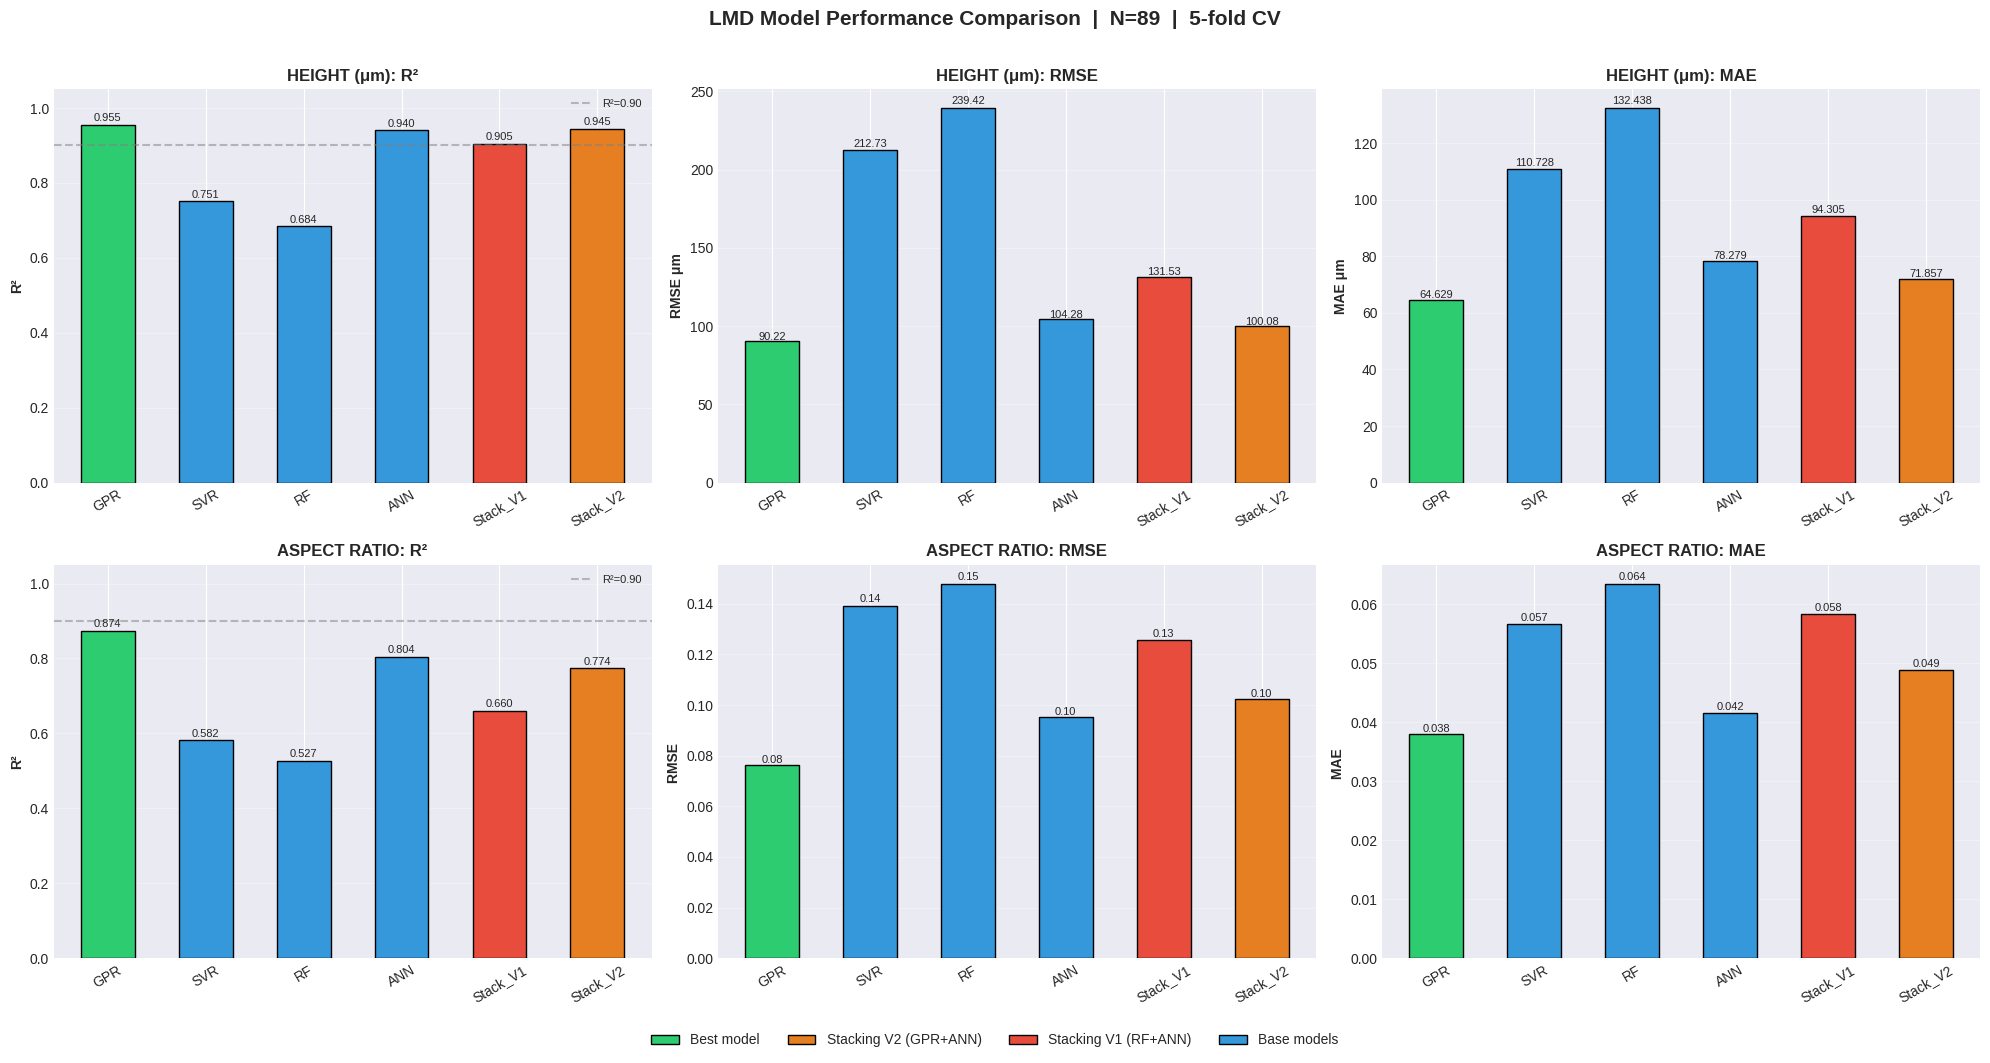

  ✓ Saved: fig1_performance_comparison.png


In [18]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 14 — VISUALISATION 1: Performance Bar Charts (all 6 models)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 9] Visualisation — Performance Bar Charts")
print("=" * 80)

model_names = list(res_H.keys())
x = np.arange(len(model_names))
width = 0.55

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
fig.suptitle('LMD Model Performance Comparison  |  N=89  |  5-fold CV',
             fontsize=15, fontweight='bold', y=1.01)

# Colour coding: green=best, orange=Stack V2, blue=others
def bar_colors(names, best):
    cols = []
    for n in names:
        if n == best:
            cols.append('#2ecc71')      # green  = best
        elif n == 'Stack_V2':
            cols.append('#e67e22')      # orange = improved stacking
        elif n == 'Stack_V1':
            cols.append('#e74c3c')      # red    = old stacking
        else:
            cols.append('#3498db')      # blue   = base models
    return cols

for row, (res, target, rmse_unit) in enumerate([
    (res_H, 'HEIGHT (μm)',    'μm'),
    (res_A, 'ASPECT RATIO',  '')
]):
    best_name = min(res, key=lambda k: res[k]['mae'])
    cols = bar_colors(model_names, best_name)

    # R²
    ax = axes[row, 0]
    vals = [res[m]['r2'] for m in model_names]
    bars = ax.bar(model_names, vals, color=cols, edgecolor='black', width=width)
    ax.set_ylabel('R²', fontweight='bold')
    ax.set_title(f'{target}: R²', fontweight='bold')
    ax.set_ylim([0, 1.05])
    ax.axhline(0.9, ls='--', color='gray', alpha=0.5, label='R²=0.90')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=30)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.01,
                f'{v:.3f}', ha='center', fontsize=8)

    # RMSE
    ax = axes[row, 1]
    vals = [res[m]['rmse'] for m in model_names]
    bars = ax.bar(model_names, vals, color=cols, edgecolor='black', width=width)
    ax.set_ylabel(f'RMSE {rmse_unit}', fontweight='bold')
    ax.set_title(f'{target}: RMSE', fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=30)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, v * 1.01,
                f'{v:.2f}', ha='center', fontsize=8)

    # MAE
    ax = axes[row, 2]
    vals = [res[m]['mae'] for m in model_names]
    bars = ax.bar(model_names, vals, color=cols, edgecolor='black', width=width)
    ax.set_ylabel(f'MAE {rmse_unit}', fontweight='bold')
    ax.set_title(f'{target}: MAE', fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=30)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, v * 1.01,
                f'{v:.3f}', ha='center', fontsize=8)

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2ecc71', edgecolor='black', label='Best model'),
    Patch(facecolor='#e67e22', edgecolor='black', label='Stacking V2 (GPR+ANN)'),
    Patch(facecolor='#e74c3c', edgecolor='black', label='Stacking V1 (RF+ANN)'),
    Patch(facecolor='#3498db', edgecolor='black', label='Base models'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4,
           fontsize=10, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.savefig('fig1_performance_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("  ✓ Saved: fig1_performance_comparison.png")




[STEP 10] Visualisation — Predicted vs Actual Scatter


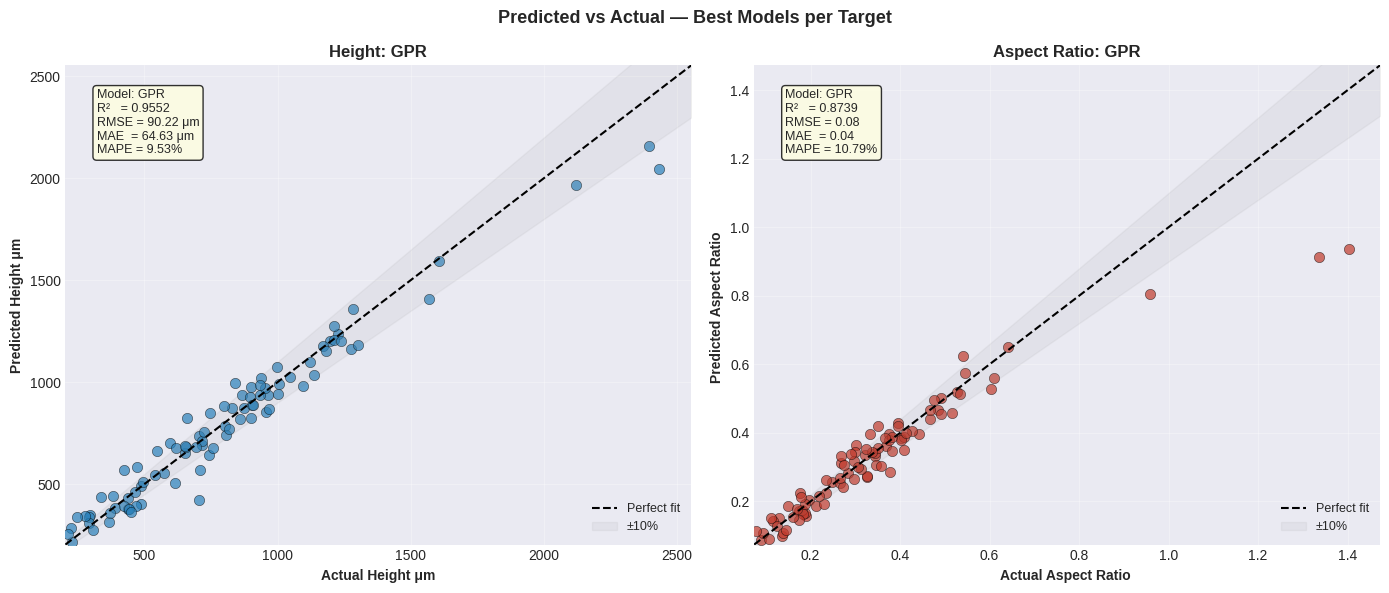

  ✓ Saved: fig2_predicted_vs_actual.png


In [19]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 15 — VISUALISATION 2: Predicted vs Actual (best models)
# ─────────────────────────────────────────────────────────────────────────────
print("\n[STEP 10] Visualisation — Predicted vs Actual Scatter")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Predicted vs Actual — Best Models per Target', fontsize=13,
             fontweight='bold')

for ax, res, best_name, label, unit, colour in [
    (axes[0], res_H, best_H, 'Height',       'μm',  '#2980b9'),
    (axes[1], res_A, best_A, 'Aspect Ratio', '',     '#c0392b')
]:
    r    = res[best_name]
    lo   = min(r['y_true'].min(), r['y_pred'].min()) * 0.95
    hi   = max(r['y_true'].max(), r['y_pred'].max()) * 1.05

    ax.scatter(r['y_true'], r['y_pred'], s=55, alpha=0.7,
               color=colour, edgecolors='black', linewidths=0.4)
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1.5, label='Perfect fit')

    # ±10% bands
    ax.fill_between([lo, hi],
                    [lo * 0.9, hi * 0.9],
                    [lo * 1.1, hi * 1.1],
                    alpha=0.08, color='gray', label='±10%')

    info = (f"Model: {best_name}\n"
            f"R²   = {r['r2']:.4f}\n"
            f"RMSE = {r['rmse']:.2f} {unit}\n"
            f"MAE  = {r['mae']:.2f} {unit}\n"
            f"MAPE = {r['mape']:.2f}%")
    ax.text(0.05, 0.95, info, transform=ax.transAxes, fontsize=9,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

    ax.set_xlabel(f'Actual {label} {unit}', fontweight='bold')
    ax.set_ylabel(f'Predicted {label} {unit}', fontweight='bold')
    ax.set_title(f'{label}: {best_name}', fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_xlim([lo, hi]); ax.set_ylim([lo, hi])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig2_predicted_vs_actual.png', dpi=300, bbox_inches='tight')
plt.show()
print("  ✓ Saved: fig2_predicted_vs_actual.png")




[STEP 11] Visualisation — Residual Analysis


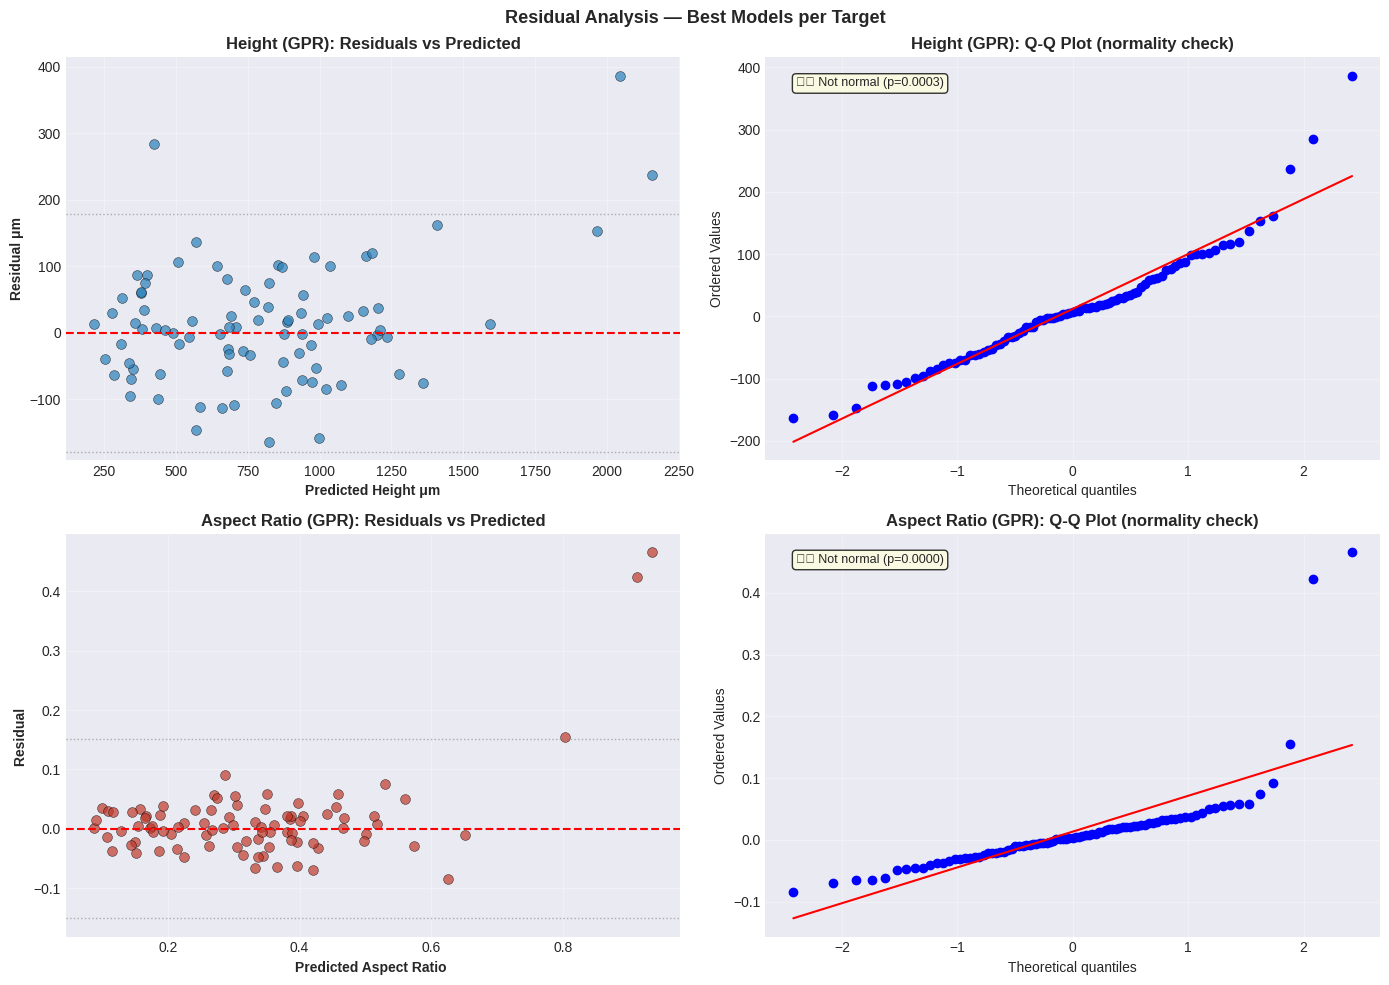

  ✓ Saved: fig3_residual_analysis.png

[IMPROVEMENT A] Stacking V1 vs V2 Head-to-Head Comparison


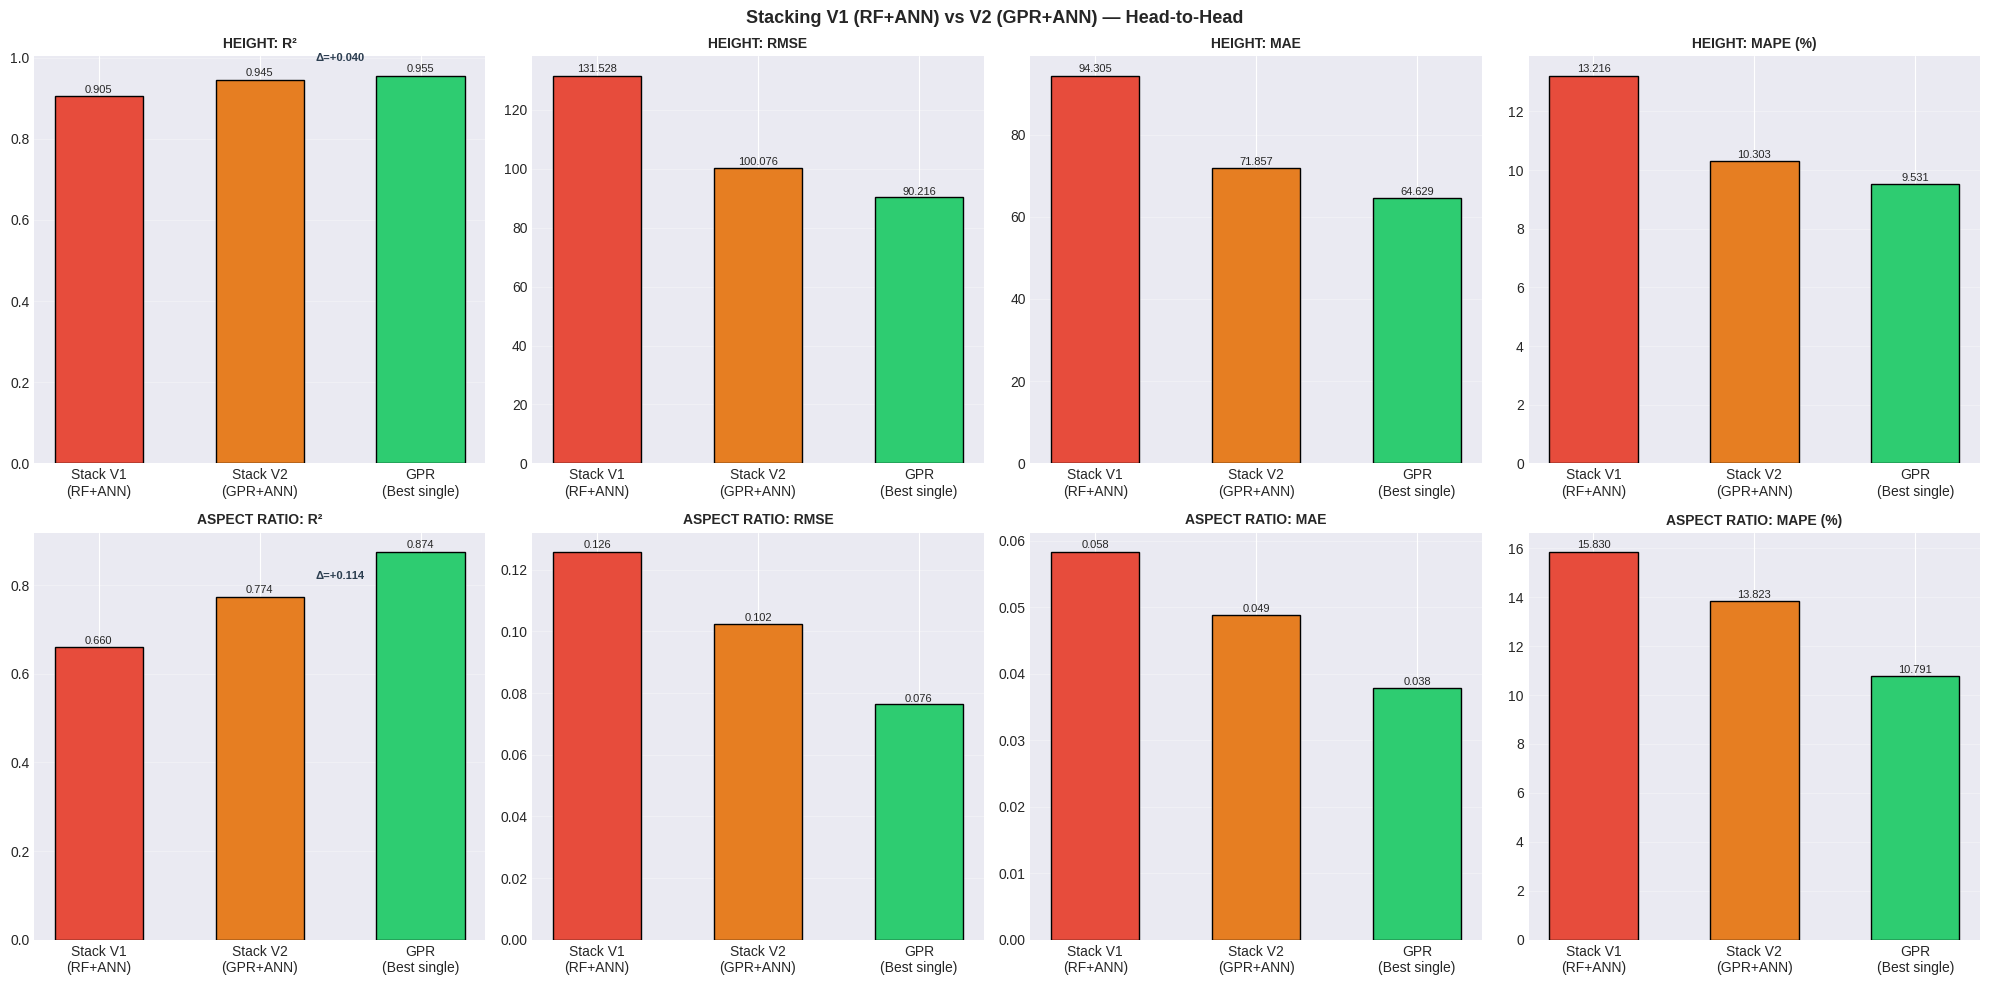

  ✓ Saved: fig4_stacking_v1_vs_v2.png

[IMPROVEMENT B] Learning Curves — Does More Data Help?
  If CV score is STILL RISING at N=89 → collect more data
  If CV score has PLATEAUED → current N is sufficient for this model
  Large train–test gap → model overfitting

  Height (GPR): ✅ Converged (gap=0.039) → N=71 may be sufficient
  Aspect Ratio (GPR): ⬆ CV still rising (+0.047) → MORE DATA WILL HELP


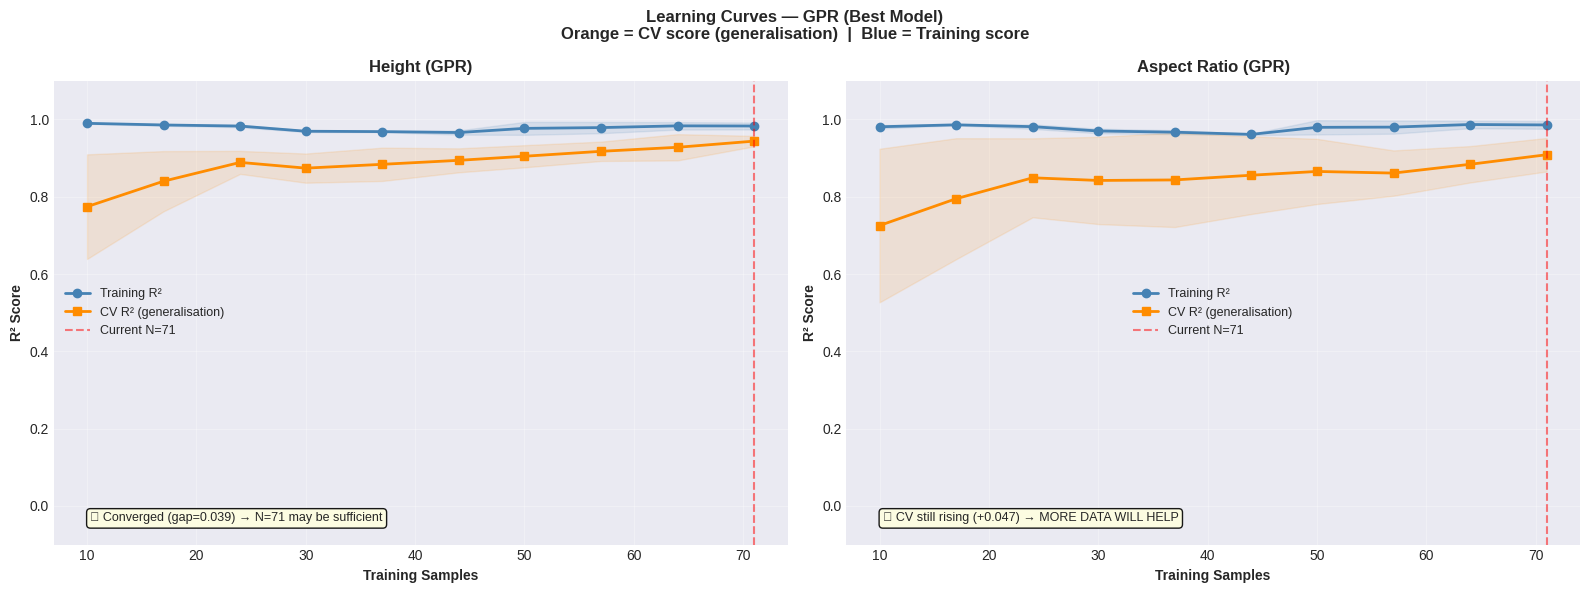

  ✓ Saved: fig5_learning_curves.png

[IMPROVEMENT C] SHAP Feature Importance (bug-fixed)
  Confirming feature alignment:
  X_scaled shape      = (89, 4)          ← 4 columns
  FEATURE_NAMES count = 4       ← must match
  ✓ Shapes match — SHAP will not crash

  Computing SHAP: RF (Height)  — TreeExplainer...
  Computing SHAP: RF (Aspect Ratio) — TreeExplainer...
  Computing SHAP: ANN (Height) — KernelExplainer+kmeans (may take ~60s)...


100%|██████████| 89/89 [00:00<00:00, 157.57it/s]


  Computing SHAP: ANN (Aspect Ratio) — KernelExplainer+kmeans...


100%|██████████| 89/89 [00:00<00:00, 163.26it/s]


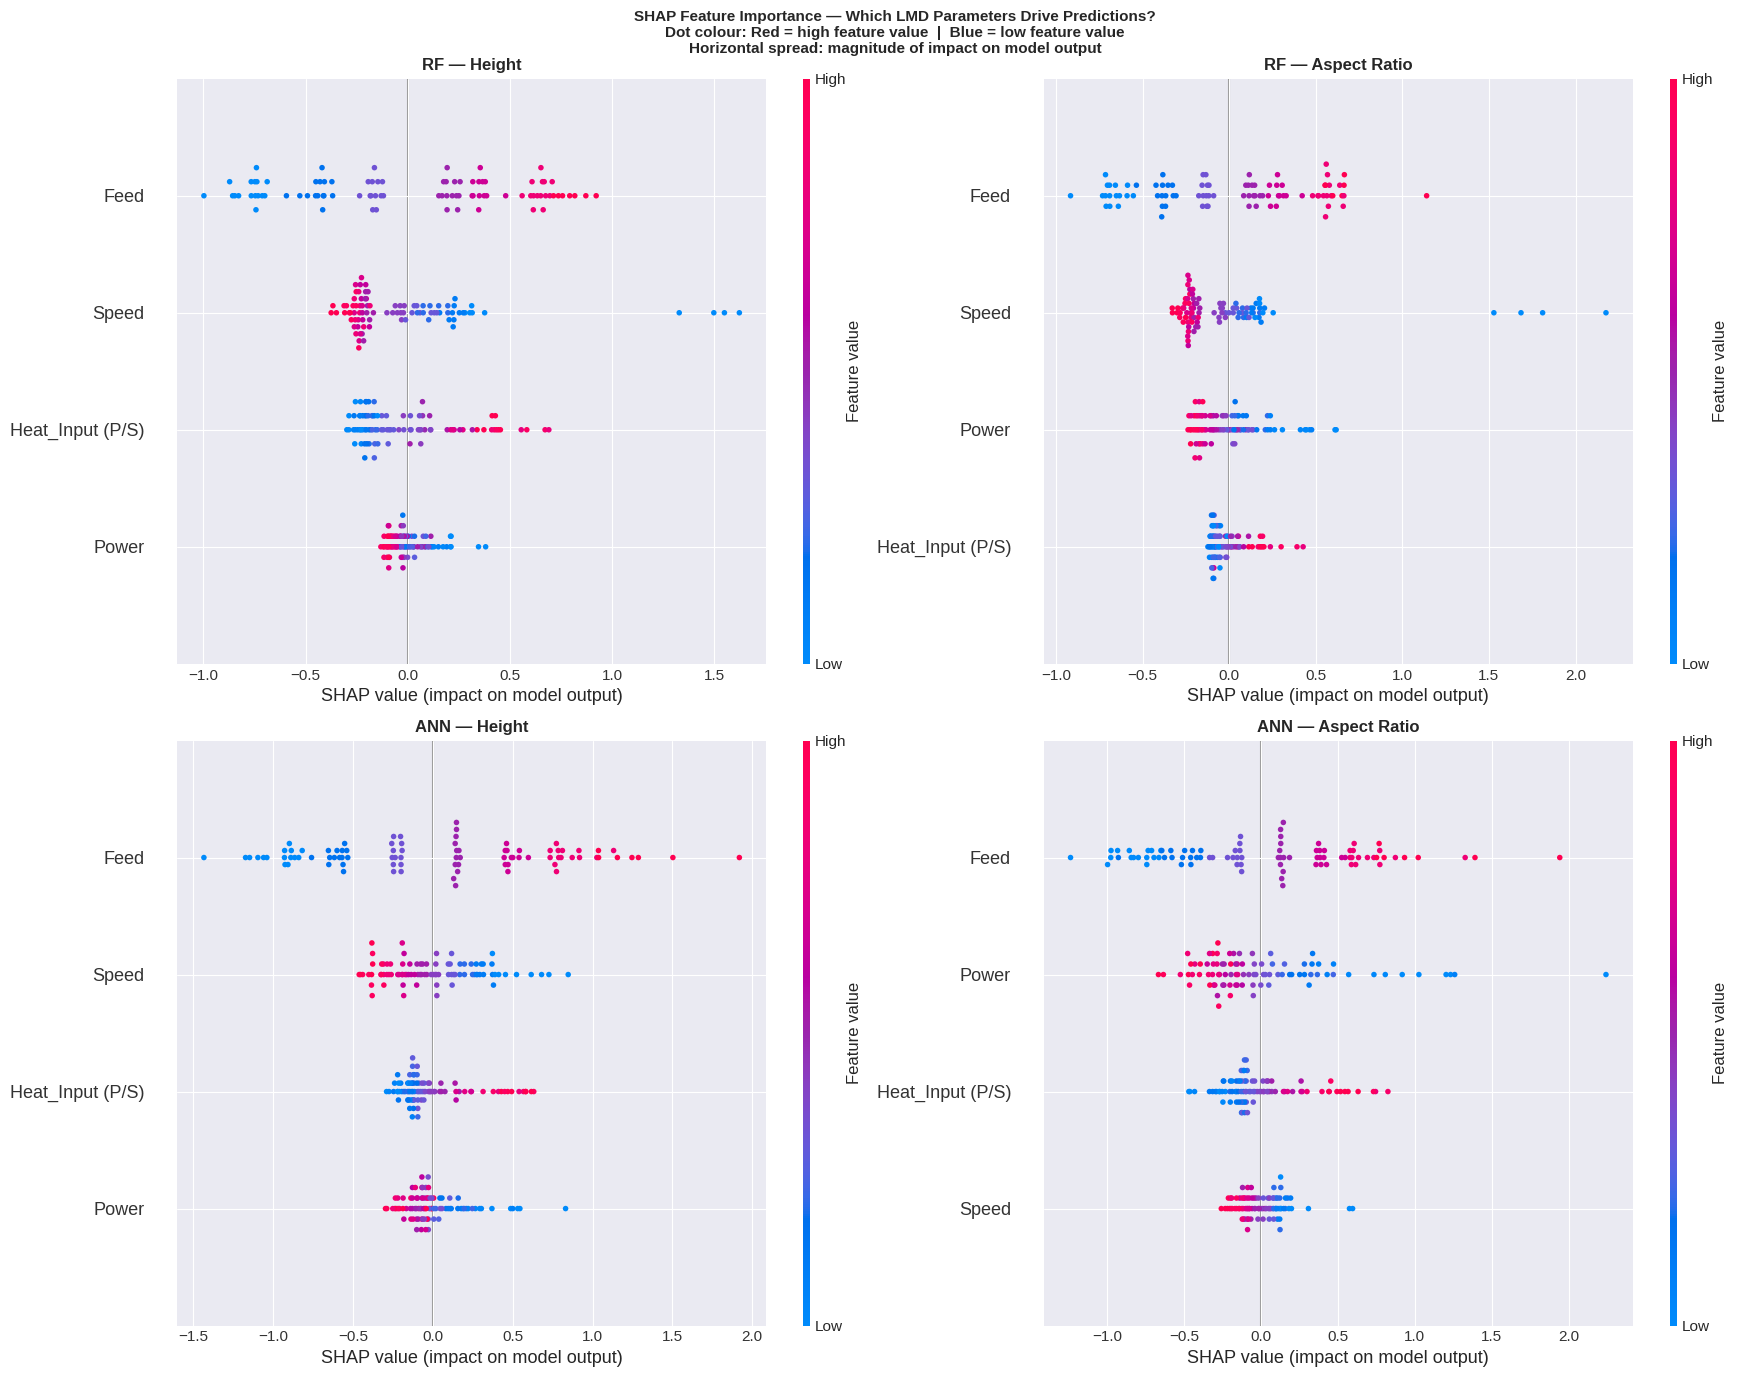

  ✓ Saved: fig6_shap_importance.png

  How to read SHAP plots:
  • Each row = one feature; length of spread = importance
  • Red dot = sample with HIGH feature value contributing positively
  • Blue dot = sample with LOW feature value contributing negatively
  • If 'Heat_Input' is top feature → derived features carry information

[IMPROVEMENT D] Multi-Output GPR — Joint Height + Aspect Ratio Prediction
  MultiOutputRegressor wraps two independent GPRs.
  If multi-output ≈ single-output → targets are independently predictable.
  If multi-output > single-output → shared information improves predictions.

  Evaluation time: 1.06s

  Metric                  Multi-GPR   Single-GPR          Δ
  ────────────────────────────────────────────────────────
  Height R²                  0.9682       0.9552    +0.0130
  Height MAE (μm)             58.83        64.63      -5.80
  Height MAPE (%)              9.11         9.11
  ────────────────────────────────────────────────────────
  Aspect R²      

In [22]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 16 — VISUALISATION 3: Residual Analysis
# ─────────────────────────────────────────────────────────────────────────────
print("\n[STEP 11] Visualisation — Residual Analysis")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Residual Analysis — Best Models per Target', fontsize=13, fontweight='bold')

for row, (res, best_name, label, unit, colour) in enumerate([
    (res_H, best_H, 'Height',       'μm',  '#2980b9'),
    (res_A, best_A, 'Aspect Ratio', '',     '#c0392b')
]):
    r = res[best_name]

    # Residuals vs predicted
    ax = axes[row, 0]
    ax.scatter(r['y_pred'], r['residuals'], s=50, alpha=0.7,
               color=colour, edgecolors='black', linewidths=0.4)
    ax.axhline(0,  color='red', lw=1.5, ls='--')
    ax.axhline( 2 * r['residuals'].std(), color='gray', lw=1, ls=':', alpha=0.6)
    ax.axhline(-2 * r['residuals'].std(), color='gray', lw=1, ls=':', alpha=0.6)
    ax.set_xlabel(f'Predicted {label} {unit}', fontweight='bold')
    ax.set_ylabel(f'Residual {unit}', fontweight='bold')
    ax.set_title(f'{label} ({best_name}): Residuals vs Predicted', fontweight='bold')
    ax.grid(alpha=0.3)

    # Q-Q plot
    ax = axes[row, 1]
    stats.probplot(r['residuals'], dist='norm', plot=ax)
    ax.set_title(f'{label} ({best_name}): Q-Q Plot (normality check)', fontweight='bold')
    norm_flag = "✅ Normal (p≥0.05)" if r['norm_p'] >= 0.05 else f"⚠️ Not normal (p={r['norm_p']:.4f})"
    ax.text(0.05, 0.95, norm_flag, transform=ax.transAxes,
            fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig3_residual_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("  ✓ Saved: fig3_residual_analysis.png")


# ─────────────────────────────────────────────────────────────────────────────
# IMPROVEMENT A — VISUALISATION 4: Stacking V1 vs V2 Direct Comparison
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[IMPROVEMENT A] Stacking V1 vs V2 Head-to-Head Comparison")
print("=" * 80)

metrics  = ['R²', 'RMSE', 'MAE', 'MAPE (%)']
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Stacking V1 (RF+ANN) vs V2 (GPR+ANN) — Head-to-Head',
             fontsize=13, fontweight='bold')

for row, (res, label) in enumerate([(res_H, 'HEIGHT'), (res_A, 'ASPECT RATIO')]):
    vals_v1  = [res['Stack_V1']['r2'],   res['Stack_V1']['rmse'],
                res['Stack_V1']['mae'],  res['Stack_V1']['mape']]
    vals_v2  = [res['Stack_V2']['r2'],   res['Stack_V2']['rmse'],
                res['Stack_V2']['mae'],  res['Stack_V2']['mape']]
    vals_gpr = [res['GPR']['r2'],        res['GPR']['rmse'],
                res['GPR']['mae'],       res['GPR']['mape']]

    for col, (metric, v1, v2, gpr) in enumerate(zip(metrics, vals_v1, vals_v2, vals_gpr)):
        ax = axes[row, col]
        bars = ax.bar(['Stack V1\n(RF+ANN)', 'Stack V2\n(GPR+ANN)', 'GPR\n(Best single)'],
                      [v1, v2, gpr],
                      color=['#e74c3c', '#e67e22', '#2ecc71'],
                      edgecolor='black', width=0.55)
        ax.set_title(f'{label}: {metric}', fontweight='bold', fontsize=10)
        ax.grid(axis='y', alpha=0.3)
        for bar, v in zip(bars, [v1, v2, gpr]):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() * 1.01 if bar.get_height() > 0 else 0.001,
                    f'{v:.3f}', ha='center', fontsize=8)

        # Improvement annotation
        if metric == 'R²':
            delta = v2 - v1
            ax.annotate(f'Δ={delta:+.3f}', xy=(1.5, max(v1, v2) * 1.05),
                        ha='center', fontsize=8, color='#2c3e50', fontweight='bold')

plt.tight_layout()
plt.savefig('fig4_stacking_v1_vs_v2.png', dpi=300, bbox_inches='tight')
plt.show()
print("  ✓ Saved: fig4_stacking_v1_vs_v2.png")


# ─────────────────────────────────────────────────────────────────────────────
# IMPROVEMENT B — LEARNING CURVES
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[IMPROVEMENT B] Learning Curves — Does More Data Help?")
print("=" * 80)
print("  If CV score is STILL RISING at N=89 → collect more data")
print("  If CV score has PLATEAUED → current N is sufficient for this model")
print("  Large train–test gap → model overfitting\n")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Learning Curves — GPR (Best Model)\n'
             'Orange = CV score (generalisation)  |  Blue = Training score',
             fontsize=12, fontweight='bold')

for ax, (model, y_sc, scaler, target_label) in zip(axes, [
    (models_H['GPR'], y_height_scaled, scaler_height, 'Height (GPR)'),
    (models_A['GPR'], y_aspect_scaled, scaler_aspect, 'Aspect Ratio (GPR)')
]):
    train_sizes, train_scores, test_scores = learning_curve(
        model,
        X_scaled, y_sc,
        train_sizes = np.linspace(0.15, 1.0, 10),   # 10 points: ~13 to 89 samples
        cv          = 5,
        scoring     = 'r2',
        n_jobs      = -1
    )

    n  = train_sizes.astype(int)
    tr = train_scores.mean(axis=1)
    ts = test_scores.mean(axis=1)
    tr_std = train_scores.std(axis=1)
    ts_std = test_scores.std(axis=1)

    ax.plot(n, tr, 'o-', color='steelblue',  lw=2, label='Training R²')
    ax.fill_between(n, tr - tr_std, tr + tr_std, alpha=0.12, color='steelblue')

    ax.plot(n, ts, 's-', color='darkorange', lw=2, label='CV R² (generalisation)')
    ax.fill_between(n, ts - ts_std, ts + ts_std, alpha=0.12, color='darkorange')

    ax.axvline(n[-1], color='red', ls='--', alpha=0.5, label=f'Current N={n[-1]}')

    ax.set_xlabel('Training Samples', fontweight='bold')
    ax.set_ylabel('R² Score',        fontweight='bold')
    ax.set_title(target_label,       fontweight='bold')
    ax.set_ylim([-0.1, 1.1])
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

    # Diagnosis text
    gap   = float(tr[-1] - ts[-1])
    trend = float(ts[-1] - ts[-3])    # slope of last 3 CV points
    if trend > 0.03:
        diag = f"⬆ CV still rising (+{trend:.3f}) → MORE DATA WILL HELP"
    elif gap > 0.15:
        diag = f"⚠ High variance gap ({gap:.3f}) → overfitting"
    else:
        diag = f"✅ Converged (gap={gap:.3f}) → N={n[-1]} may be sufficient"

    ax.text(0.05, 0.05, diag, transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))
    print(f"  {target_label}: {diag}")

plt.tight_layout()
plt.savefig('fig5_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print("  ✓ Saved: fig5_learning_curves.png")


# ─────────────────────────────────────────────────────────────────────────────
# IMPROVEMENT C — SHAP FEATURE IMPORTANCE (CORRECTED)
# Bug fix: feature_names now has 4 entries matching X_scaled (4 columns)
# Uses TreeExplainer (RF) and KernelExplainer+kmeans (ANN) correctly
# ─────────────────────────────────────────────────────────────────────────────
if SHAP_AVAILABLE:
    print("\n" + "=" * 80)
    print("[IMPROVEMENT C] SHAP Feature Importance (bug-fixed)")
    print("=" * 80)
    print("  Confirming feature alignment:")
    print(f"  X_scaled shape      = {X_scaled.shape}          ← {X_scaled.shape[1]} columns")
    print(f"  FEATURE_NAMES count = {len(FEATURE_NAMES)}       ← must match")
    assert X_scaled.shape[1] == len(FEATURE_NAMES), \
        f"MISMATCH: {X_scaled.shape[1]} cols vs {len(FEATURE_NAMES)} names"
    print("  ✓ Shapes match — SHAP will not crash\n")

    # Refit models on full data (SHAP needs fitted estimators, not CV objects)
    rf_h_fit = models_H['RF'];  rf_h_fit.fit(X_scaled, y_height_scaled)
    rf_a_fit = models_A['RF'];  rf_a_fit.fit(X_scaled, y_aspect_scaled)
    ann_h_fit = models_H['ANN']; ann_h_fit.fit(X_scaled, y_height_scaled)
    ann_a_fit = models_A['ANN']; ann_a_fit.fit(X_scaled, y_aspect_scaled)

    fig = plt.figure(figsize=(18, 14))
    fig.suptitle(
        'SHAP Feature Importance — Which LMD Parameters Drive Predictions?\n'
        'Dot colour: Red = high feature value  |  Blue = low feature value\n'
        'Horizontal spread: magnitude of impact on model output',
        fontsize=11, fontweight='bold'
    )
    gs = gridspec.GridSpec(2, 2, figure=fig)

    # ── RF Height (TreeExplainer — exact, fast) ───────────────────────────────
    print("  Computing SHAP: RF (Height)  — TreeExplainer...")
    ax1 = fig.add_subplot(gs[0, 0])
    plt.sca(ax1)
    exp_rf_h  = shap.TreeExplainer(rf_h_fit)
    sv_rf_h   = exp_rf_h.shap_values(X_scaled)
    shap.summary_plot(sv_rf_h, X_scaled, feature_names=FEATURE_NAMES,
                      show=False, plot_size=None)
    ax1.set_title('RF — Height', fontweight='bold')

    # ── RF Aspect Ratio ────────────────────────────────────────────────────────
    print("  Computing SHAP: RF (Aspect Ratio) — TreeExplainer...")
    ax2 = fig.add_subplot(gs[0, 1])
    plt.sca(ax2)
    exp_rf_a  = shap.TreeExplainer(rf_a_fit)
    sv_rf_a   = exp_rf_a.shap_values(X_scaled)
    shap.summary_plot(sv_rf_a, X_scaled, feature_names=FEATURE_NAMES,
                      show=False, plot_size=None)
    ax2.set_title('RF — Aspect Ratio', fontweight='bold')

    # ── ANN Height (KernelExplainer + kmeans background) ─────────────────────
    # kmeans(X, k) compresses 89 samples to k representative background points
    # This speeds up KernelExplainer while preserving feature distribution
    print("  Computing SHAP: ANN (Height) — KernelExplainer+kmeans (may take ~60s)...")
    bg_h      = shap.kmeans(X_scaled, 30)
    exp_ann_h = shap.KernelExplainer(ann_h_fit.predict, bg_h)
    sv_ann_h  = exp_ann_h.shap_values(X_scaled, nsamples=150, l1_reg='num_features(4)')

    ax3 = fig.add_subplot(gs[1, 0])
    plt.sca(ax3)
    shap.summary_plot(sv_ann_h, X_scaled, feature_names=FEATURE_NAMES,
                      show=False, plot_size=None)
    ax3.set_title('ANN — Height', fontweight='bold')

    # ── ANN Aspect Ratio ───────────────────────────────────────────────────────
    print("  Computing SHAP: ANN (Aspect Ratio) — KernelExplainer+kmeans...")
    bg_a      = shap.kmeans(X_scaled, 30)
    exp_ann_a = shap.KernelExplainer(ann_a_fit.predict, bg_a)
    sv_ann_a  = exp_ann_a.shap_values(X_scaled, nsamples=150, l1_reg='num_features(4)')

    ax4 = fig.add_subplot(gs[1, 1])
    plt.sca(ax4)
    shap.summary_plot(sv_ann_a, X_scaled, feature_names=FEATURE_NAMES,
                      show=False, plot_size=None)
    ax4.set_title('ANN — Aspect Ratio', fontweight='bold')

    plt.tight_layout()
    plt.savefig('fig6_shap_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("  ✓ Saved: fig6_shap_importance.png")
    print("\n  How to read SHAP plots:")
    print("  • Each row = one feature; length of spread = importance")
    print("  • Red dot = sample with HIGH feature value contributing positively")
    print("  • Blue dot = sample with LOW feature value contributing negatively")
    print("  • If 'Heat_Input' is top feature → derived features carry information")
else:
    print("\n  ⚠️  SHAP skipped — install with: pip install shap")


# ─────────────────────────────────────────────────────────────────────────────
# IMPROVEMENT D — MULTI-OUTPUT GPR (corrected: real kernel, full evaluation)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[IMPROVEMENT D] Multi-Output GPR — Joint Height + Aspect Ratio Prediction")
print("=" * 80)
print("  MultiOutputRegressor wraps two independent GPRs.")
print("  If multi-output ≈ single-output → targets are independently predictable.")
print("  If multi-output > single-output → shared information improves predictions.\n")

# ── BUG FIX: pass actual kernel (not Python ellipsis '...') ──────────────────
# Use the best kernel identified during single-output hyperparameter tuning
best_kernel_h = params_H['GPR'].get('kernel', C(1.0) * RBF(1.0))
best_alpha_h  = params_H['GPR'].get('alpha',  0.01)

multi_gpr = MultiOutputRegressor(
    GaussianProcessRegressor(
        kernel             = C(1.0) * RBF(1.0),   # same kernel class as tuned GPR
        alpha              = best_alpha_h,          # regularisation from tuning
        n_restarts_optimizer = 5,
        random_state       = 42
    ),
    n_jobs=-1
)

# Joint target matrix (N × 2)
Y_joint = np.column_stack([y_height_scaled, y_aspect_scaled])

# Evaluate with the same 5-fold CV as all other models
kf = KFold(n_splits=5, shuffle=True, random_state=42)

t0 = time.time()
Y_pred_joint = cross_val_predict(multi_gpr, X_scaled, Y_joint, cv=kf)
elapsed = time.time() - t0

# Back-transform both outputs to original units
h_pred_orig = scaler_height.inverse_transform(Y_pred_joint[:, 0].reshape(-1, 1)).ravel()
a_pred_orig = scaler_aspect.inverse_transform(Y_pred_joint[:, 1].reshape(-1, 1)).ravel()
h_true_orig = scaler_height.inverse_transform(y_height_scaled.reshape(-1, 1)).ravel()
a_true_orig = scaler_aspect.inverse_transform(y_aspect_scaled.reshape(-1, 1)).ravel()

# Metrics
r2_h_mg   = r2_score(h_true_orig, h_pred_orig)
mae_h_mg  = mean_absolute_error(h_true_orig, h_pred_orig)
mape_h_mg = mean_absolute_percentage_error(h_true_orig, h_pred_orig) * 100

r2_a_mg   = r2_score(a_true_orig, a_pred_orig)
mae_a_mg  = mean_absolute_error(a_true_orig, a_pred_orig)
mape_a_mg = mean_absolute_percentage_error(a_true_orig, a_pred_orig) * 100

# Reference: single-output GPR
r2_h_sg  = res_H['GPR']['r2'];   mae_h_sg  = res_H['GPR']['mae']
r2_a_sg  = res_A['GPR']['r2'];   mae_a_sg  = res_A['GPR']['mae']

print(f"  Evaluation time: {elapsed:.2f}s\n")
print(f"  {'Metric':<20} {'Multi-GPR':>12} {'Single-GPR':>12} {'Δ':>10}")
print(f"  {'─'*56}")
print(f"  {'Height R²':<20} {r2_h_mg:>12.4f} {r2_h_sg:>12.4f} {r2_h_mg-r2_h_sg:>+10.4f}")
print(f"  {'Height MAE (μm)':<20} {mae_h_mg:>12.2f} {mae_h_sg:>12.2f} {mae_h_mg-mae_h_sg:>+10.2f}")
print(f"  {'Height MAPE (%)':<20} {mape_h_mg:>12.2f} {mape_h_mg:>12.2f}")
print(f"  {'─'*56}")
print(f"  {'Aspect R²':<20} {r2_a_mg:>12.4f} {r2_a_sg:>12.4f} {r2_a_mg-r2_a_sg:>+10.4f}")
print(f"  {'Aspect MAE':<20} {mae_a_mg:>12.4f} {mae_a_sg:>12.4f} {mae_a_mg-mae_a_sg:>+10.4f}")
print(f"  {'Aspect MAPE (%)':<20} {mape_a_mg:>12.2f} {mape_a_mg:>12.2f}")

# Thesis conclusion
delta_h = r2_h_mg - r2_h_sg
delta_a = r2_a_mg - r2_a_sg
print(f"\n  Thesis interpretation:")
if delta_h > 0.005 or delta_a > 0.005:
    print("  ✅ Multi-output GPR improves at least one target →")
    print("     Joint modelling captures cross-target correlations")
    print("     (e.g. height and aspect ratio share physics-driven variance)")
elif abs(delta_h) < 0.005 and abs(delta_a) < 0.005:
    print("  ➡ Multi-output GPR ≈ single-output GPR →")
    print("    Height and aspect ratio are independently predictable given {P, S, F}")
    print("    Single-output models are sufficient; no benefit to joint modelling")
else:
    print("  ⚠ Mixed result — check per-target Δ values above")

# Save multi-output results for thesis table
mg_summary = pd.DataFrame({
    'Target'   : ['Height', 'Aspect Ratio'],
    'Model'    : ['Multi-GPR', 'Multi-GPR'],
    'R²'       : [round(r2_h_mg, 4), round(r2_a_mg, 4)],
    'MAE'      : [round(mae_h_mg, 4), round(mae_a_mg, 4)],
    'MAPE (%)'  : [round(mape_h_mg, 2), round(mape_a_mg, 2)],
    'vs Single GPR Δ R²': [round(delta_h, 4), round(delta_a, 4)]
})
mg_summary.to_csv('multi_output_gpr_results.csv', index=False)
print("\n  ✓ Multi-output results saved: multi_output_gpr_results.csv")



In [23]:

# ─────────────────────────────────────────────────────────────────────────────
# CELL 17 — SAVE BEST MODELS FOR OPTIMISATION
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("[STEP 12] Saving Best Models for Deployment / Optimisation")
print("=" * 80)

import joblib

# Identify overall best per target
best_H_final = min(res_H, key=lambda k: res_H[k]['mae'])
best_A_final = min(res_A, key=lambda k: res_A[k]['mae'])

# Save best models
joblib.dump(models_H[best_H_final], 'best_model_height.pkl')
joblib.dump(models_A[best_A_final], 'best_model_aspect.pkl')

# Save scalers (REQUIRED for prediction — do not lose these)
joblib.dump(scaler_X,      'scaler_X.pkl')
joblib.dump(scaler_height, 'scaler_height.pkl')
joblib.dump(scaler_aspect, 'scaler_aspect.pkl')

print(f"  ✓ Best HEIGHT model    : {best_H_final}  (MAE={res_H[best_H_final]['mae']:.2f} μm)")
print(f"  ✓ Best ASPECT model    : {best_A_final}  (MAE={res_A[best_A_final]['mae']:.4f})")
print("  ✓ All scalers saved")

# ─────────────────────────────────────────────────────────────────────────────
# HOW TO USE SAVED MODELS FOR PREDICTION
# ─────────────────────────────────────────────────────────────────────────────
print("""
  ─────────────────────────────────────────────────────────────────────────
  TO PREDICT ON NEW PROCESS PARAMETERS:
  ─────────────────────────────────────────────────────────────────────────
  import joblib, numpy as np

  model_H   = joblib.load('best_model_height.pkl')
  model_A   = joblib.load('best_model_aspect.pkl')
  scaler_X  = joblib.load('scaler_X.pkl')
  scaler_H  = joblib.load('scaler_height.pkl')
  scaler_A  = joblib.load('scaler_aspect.pkl')

  # New parameters: [Power (W), Speed (mm/s), Feed (g/min)]
  new = np.array([[2000, 1.0, 5.0]])
  heat_in = new[:, 0] / (new[:, 1] + 1e-9)
  new_eng = np.column_stack([new, heat_in])       # add Heat_Input feature

  new_scaled = scaler_X.transform(new_eng)

  h_scaled = model_H.predict(new_scaled)
  a_scaled = model_A.predict(new_scaled)

  height_um     = scaler_H.inverse_transform(h_scaled.reshape(-1,1))[0,0]
  aspect_ratio  = scaler_A.inverse_transform(a_scaled.reshape(-1,1))[0,0]

  print(f"Predicted Height       : {height_um:.2f} μm")
  print(f"Predicted Aspect Ratio : {aspect_ratio:.4f}")
  ─────────────────────────────────────────────────────────────────────────
""")

# ─────────────────────────────────────────────────────────────────────────────
# FINAL SUMMARY
# ─────────────────────────────────────────────────────────────────────────────
print("=" * 80)
print("  ALL STEPS COMPLETE")
print("=" * 80)
print(f"\n  Files generated:")
print("   fig1_performance_comparison.png  — Bar charts: all 6 models × 3 metrics")
print("   fig2_predicted_vs_actual.png     — Scatter: best model per target")
print("   fig3_residual_analysis.png       — Residuals + Q-Q plots")
print("   fig4_stacking_v1_vs_v2.png       — Stack V1 vs V2 head-to-head")
print("   fig5_learning_curves.png         — Data sufficiency diagnosis")
print("   fig6_shap_importance.png         — Feature importance (if SHAP installed)")
print("   height_model_comparison_final.csv")
print("   aspect_model_comparison_final.csv")
print("   multi_output_gpr_results.csv")
print("   best_model_height.pkl")
print("   best_model_aspect.pkl")
print("   scaler_X.pkl  /  scaler_height.pkl  /  scaler_aspect.pkl")
print()
print(f"  ★ Best HEIGHT model    : {best_H_final}")
print(f"  ★ Best ASPECT model    : {best_A_final}")
print()
print("  Ready for: inverse optimisation (NSGA-II / PSO)")
print("=" * 80)



[STEP 12] Saving Best Models for Deployment / Optimisation
  ✓ Best HEIGHT model    : GPR  (MAE=64.63 μm)
  ✓ Best ASPECT model    : GPR  (MAE=0.0379)
  ✓ All scalers saved

  ─────────────────────────────────────────────────────────────────────────
  TO PREDICT ON NEW PROCESS PARAMETERS:
  ─────────────────────────────────────────────────────────────────────────
  import joblib, numpy as np

  model_H   = joblib.load('best_model_height.pkl')
  model_A   = joblib.load('best_model_aspect.pkl')
  scaler_X  = joblib.load('scaler_X.pkl')
  scaler_H  = joblib.load('scaler_height.pkl')
  scaler_A  = joblib.load('scaler_aspect.pkl')

  # New parameters: [Power (W), Speed (mm/s), Feed (g/min)]
  new = np.array([[2000, 1.0, 5.0]])
  heat_in = new[:, 0] / (new[:, 1] + 1e-9)
  new_eng = np.column_stack([new, heat_in])       # add Heat_Input feature

  new_scaled = scaler_X.transform(new_eng)

  h_scaled = model_H.predict(new_scaled)
  a_scaled = model_A.predict(new_scaled)

  height_um     = sca